In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
df=pd.read_csv(r"D:\OneDrive\Desktop\covid 19\covid19_patient_outcome.csv")
df.head()

,Patient_ID,Age,Gender,Fever,Cough,Breathing_Difficulty,Diabetes,Hypertension,Heart_Disease,Oxygen_Level,Respiratory_Rate,Temperature,Hospitalized,ICU_Required,Outcome
0,1,61.0,Male,0,0,0,0.0,1.0,0,97.5,19.3,36.6,1,0,Recovered
1,2,50.0,Male,1,1,0,0.0,0.0,0,92.7,70.0,36.6,1,0,Recovered
2,3,64.0,Female,1,0,0,0.0,1.0,0,96.5,16.2,36.5,0,0,Recovered
3,4,79.0,Female,0,1,1,0.0,1.0,0,94.5,24.6,37.3,1,1,Death
4,5,48.0,Male,1,1,0,1.0,0.0,0,96.9,18.9,37.7,1,0,ICU


In [3]:
df.shape

(1000, 15)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Patient_ID            1000 non-null   int64  
 1   Age                   996 non-null    float64
 2   Gender                996 non-null    str    
 3   Fever                 1000 non-null   int64  
 4   Cough                 1000 non-null   int64  
 5   Breathing_Difficulty  1000 non-null   int64  
 6   Diabetes              997 non-null    float64
 7   Hypertension          995 non-null    float64
 8   Heart_Disease         1000 non-null   int64  
 9   Oxygen_Level          997 non-null    float64
 10  Respiratory_Rate      997 non-null    float64
 11  Temperature           995 non-null    float64
 12  Hospitalized          1000 non-null   int64  
 13  ICU_Required          1000 non-null   int64  
 14  Outcome               1000 non-null   str    
dtypes: float64(6), int64(7), str(2)
m

In [5]:
df.describe()

,Patient_ID,Age,Fever,Cough,Breathing_Difficulty,Diabetes,Hypertension,Heart_Disease,Oxygen_Level,Respiratory_Rate,Temperature,Hospitalized,ICU_Required
count,1000.000000,996.000000,1000.000000,1000.000000,1000.000000,997.000000,995.000000,1000.000000,997.000000,997.000000,995.000000,1000.000000,1000.00000
mean,500.500000,52.435743,0.626000,0.700000,0.568000,0.185557,0.202010,0.095000,93.461284,19.983250,37.246834,0.617000,0.42700
std,288.819436,17.609696,0.484106,0.458487,0.495602,0.388944,0.401702,0.293362,4.753798,4.714816,0.748935,0.486362,0.49489
min,1.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,45.000000,10.000000,35.900000,0.000000,0.00000
25%,250.750000,40.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,90.700000,17.500000,36.800000,0.000000,0.00000
50%,500.500000,52.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,93.100000,19.800000,37.300000,1.000000,0.00000
75%,750.250000,64.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,96.300000,22.100000,37.500000,1.000000,1.00000
max,1000.000000,125.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,155.000000,80.000000,48.000000,1.000000,1.00000


In [6]:
df.isnull().sum()

Patient_ID              0
Age                     4
Gender                  4
Fever                   0
Cough                   0
Breathing_Difficulty    0
Diabetes                3
Hypertension            5
Heart_Disease           0
Oxygen_Level            3
Respiratory_Rate        3
Temperature             5
Hospitalized            0
ICU_Required            0
Outcome                 0
dtype: int64

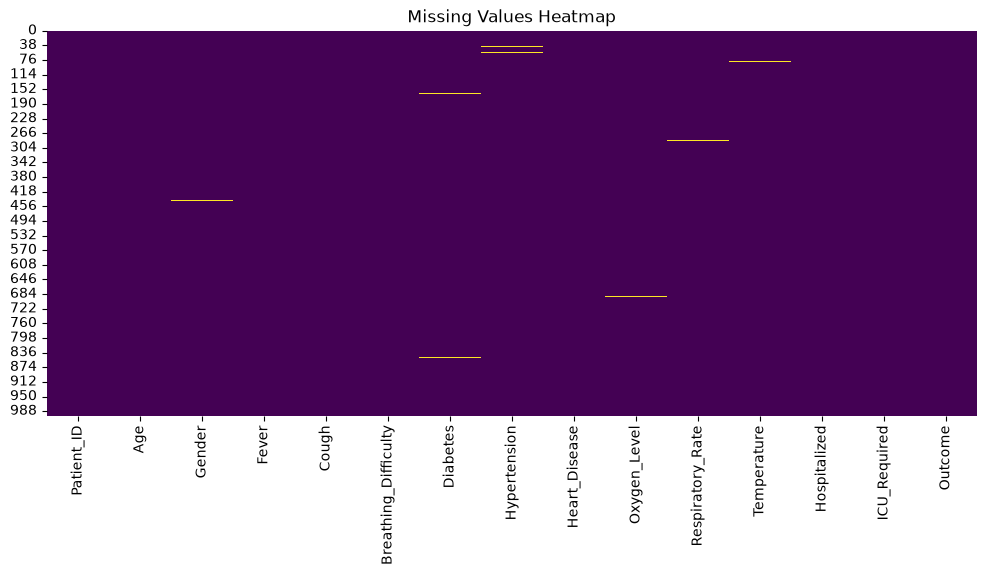

In [7]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap="viridis"
)

plt.title("Missing Values Heatmap")
plt.show()

In [8]:
# Numerical columns
numerical_columns = df.select_dtypes(
    include=np.number
).columns

for column in numerical_columns:
    
    if column != "Patient_ID":
        df[column] = df[column].fillna(
            df[column].median()
        )


# Categorical columns
categorical_columns = df.select_dtypes(
    include="object"
).columns

for column in categorical_columns:
    
    if column != "Outcome":
        df[column] = df[column].fillna(
            df[column].mode()[0]
        )

In [9]:
print(df.isnull().sum())

Patient_ID              0
Age                     0
Gender                  0
Fever                   0
Cough                   0
Breathing_Difficulty    0
Diabetes                0
Hypertension            0
Heart_Disease           0
Oxygen_Level            0
Respiratory_Rate        0
Temperature             0
Hospitalized            0
ICU_Required            0
Outcome                 0
dtype: int64


In [10]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [12]:
print(df["Outcome"].value_counts())

Outcome
Death        405
Recovered    368
ICU          227
Name: count, dtype: int64


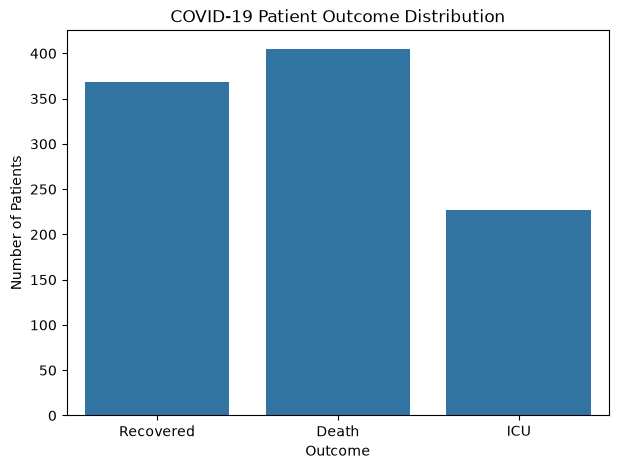

In [13]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Outcome"
)

plt.title("COVID-19 Patient Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")

plt.show()

In [15]:
for column in numeric_features:
    
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = df[
        (df[column] < lower) |
        (df[column] > upper)
    ]
    
    print(
        column,
        "outliers:",
        len(outliers)
    )

Age outliers: 4
Oxygen_Level outliers: 4
Respiratory_Rate outliers: 8
Temperature outliers: 5


In [16]:
for column in numeric_features:
    
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    df[column] = df[column].clip(
        lower,
        upper
    )

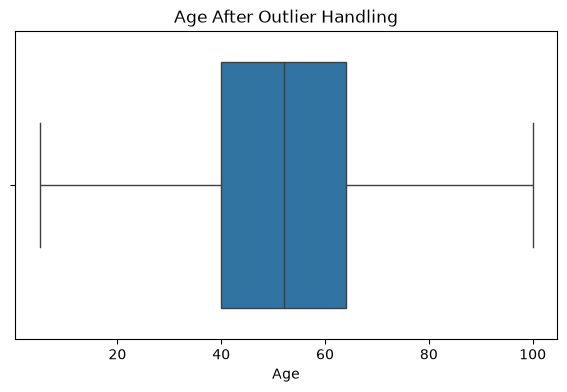

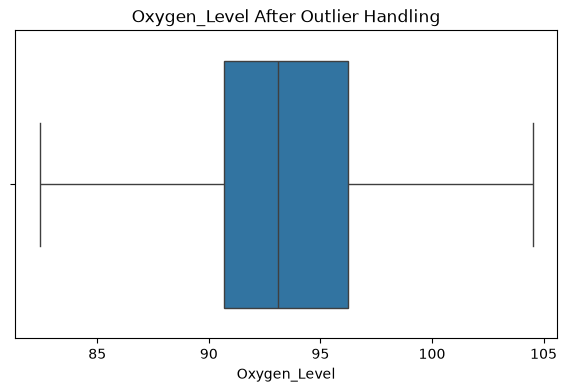

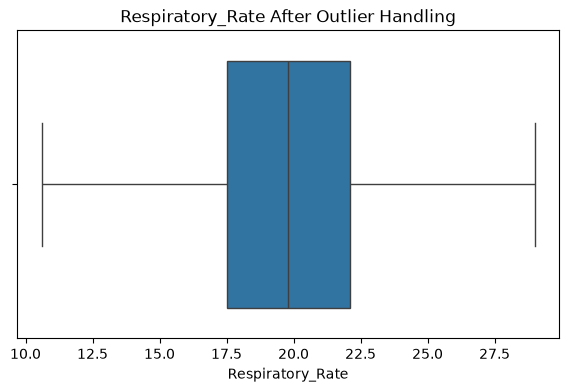

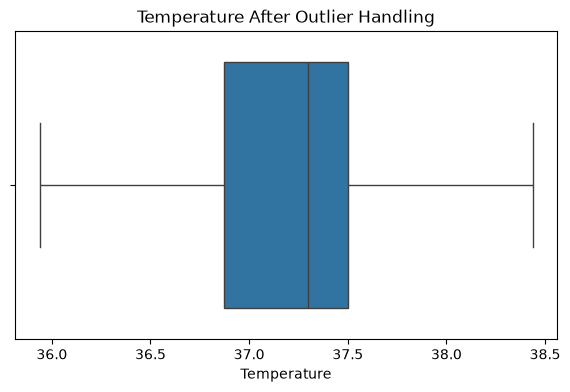

In [17]:
for column in numeric_features:
    
    plt.figure(figsize=(7, 4))
    
    sns.boxplot(
        data=df,
        x=column
    )
    
    plt.title(
        f"{column} After Outlier Handling"
    )
    
    plt.show()

In [18]:
gender_encoder = LabelEncoder()

df["Gender"] = gender_encoder.fit_transform(
    df["Gender"]
)

df.head()

,Patient_ID,Age,Gender,Fever,Cough,Breathing_Difficulty,Diabetes,Hypertension,Heart_Disease,Oxygen_Level,Respiratory_Rate,Temperature,Hospitalized,ICU_Required,Outcome
0,1,61.0,1,0,0,0,0.0,1.0,0,97.5,19.3,36.6,1,0,Recovered
1,2,50.0,1,1,1,0,0.0,0.0,0,92.7,29.0,36.6,1,0,Recovered
2,3,64.0,0,1,0,0,0.0,1.0,0,96.5,16.2,36.5,0,0,Recovered
3,4,79.0,0,0,1,1,0.0,1.0,0,94.5,24.6,37.3,1,1,Death
4,5,48.0,1,1,1,0,1.0,0.0,0,96.9,18.9,37.7,1,0,ICU


In [19]:
outcome_encoder = LabelEncoder()

df["Outcome"] = outcome_encoder.fit_transform(
    df["Outcome"]
)

print(
    "Outcome classes:",
    outcome_encoder.classes_
)

Outcome classes: ['Death' 'ICU' 'Recovered']


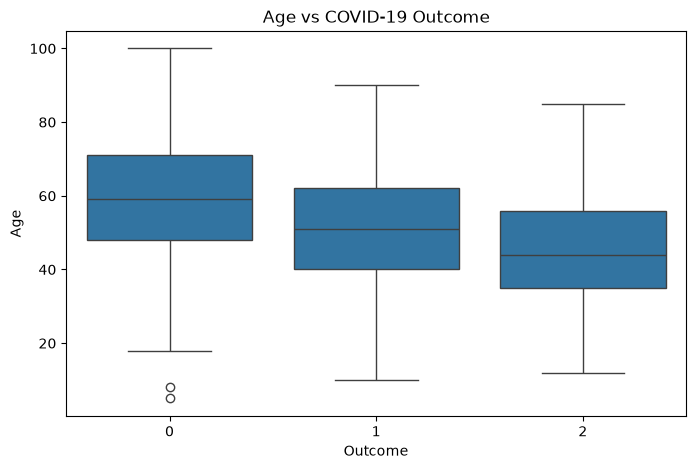

In [20]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Outcome",
    y="Age"
)

plt.title("Age vs COVID-19 Outcome")

plt.show()

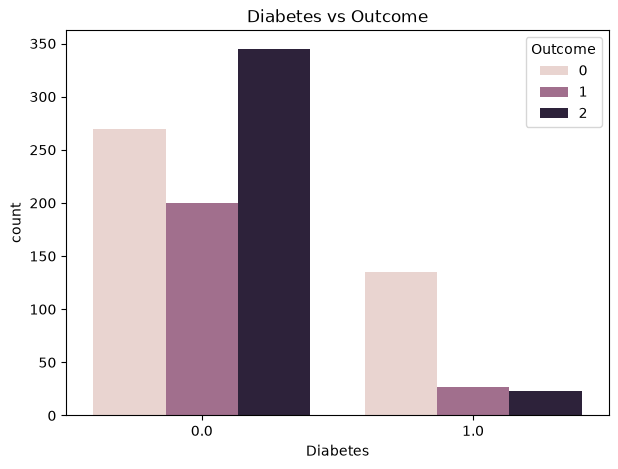

In [21]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Diabetes",
    hue="Outcome"
)

plt.title(
    "Diabetes vs Outcome"
)

plt.show()

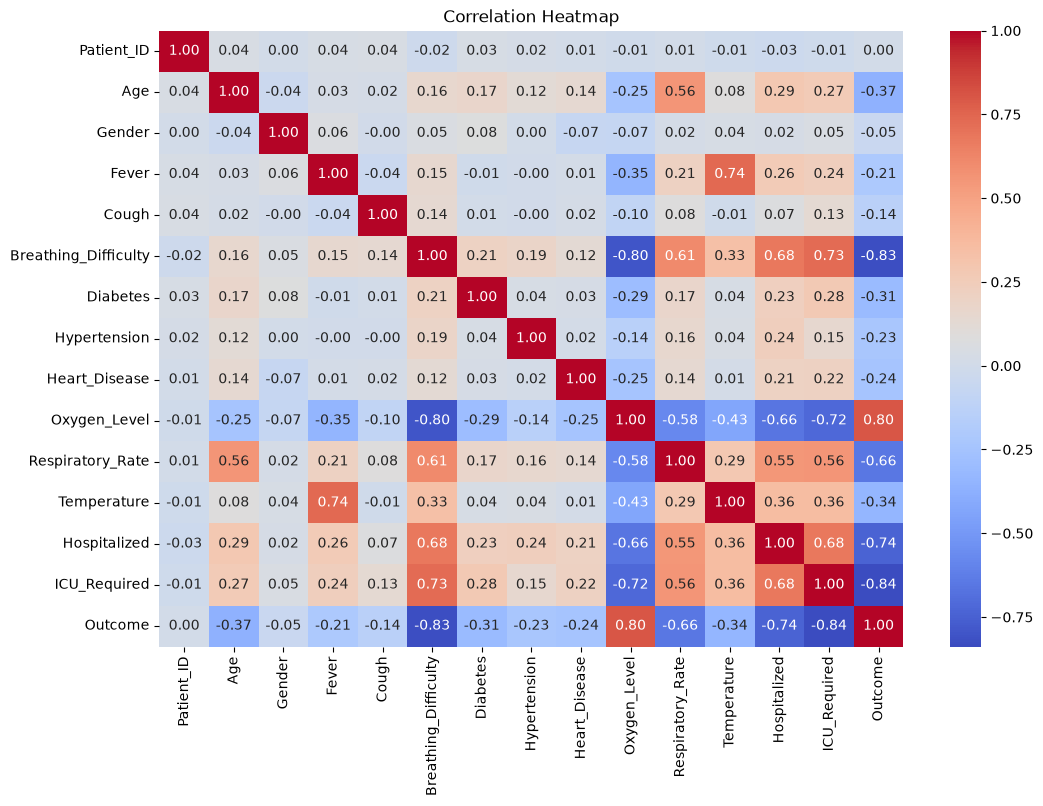

In [22]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [23]:
X = df.drop(
    ["Outcome", "Patient_ID"],
    axis=1
)

y = df["Outcome"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1000, 13)
y shape: (1000,)


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (800, 13)
Testing data: (200, 13)


In [25]:
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=15,
    min_samples_split=4,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [26]:
model.fit(
    X_train,
    y_train
)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [27]:
y_pred = model.predict(X_test)

print(y_pred[:20])

[0 0 2 1 0 1 1 0 1 0 0 0 2 0 2 0 2 1 1 2]


In [28]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

print(
    "Accuracy:",
    accuracy
)

print(
    "Accuracy percentage:",
    accuracy * 100,
    "%"
)

Accuracy: 0.85
Accuracy percentage: 85.0 %


In [29]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=outcome_encoder.classes_
    )
)

              precision    recall  f1-score   support

       Death       0.94      0.94      0.94        81
         ICU       0.66      0.69      0.67        45
   Recovered       0.88      0.85      0.86        74

    accuracy                           0.85       200
   macro avg       0.82      0.83      0.83       200
weighted avg       0.85      0.85      0.85       200



In [30]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[76  5  0]
 [ 5 31  9]
 [ 0 11 63]]


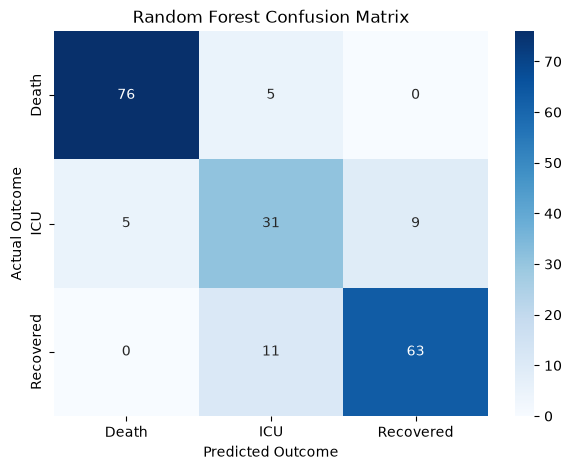

In [31]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=outcome_encoder.classes_,
    yticklabels=outcome_encoder.classes_
)

plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.title(
    "Random Forest Confusion Matrix"
)

plt.show()

In [32]:
feature_importance = pd.DataFrame({

    "Feature": X.columns,

    "Importance": model.feature_importances_

})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                 Feature  Importance
8           Oxygen_Level    0.266801
12          ICU_Required    0.164232
4   Breathing_Difficulty    0.148620
9       Respiratory_Rate    0.116076
0                    Age    0.111722
11          Hospitalized    0.077777
10           Temperature    0.042628
5               Diabetes    0.018675
3                  Cough    0.012483
6           Hypertension    0.011285
7          Heart_Disease    0.011005
1                 Gender    0.010390
2                  Fever    0.008305


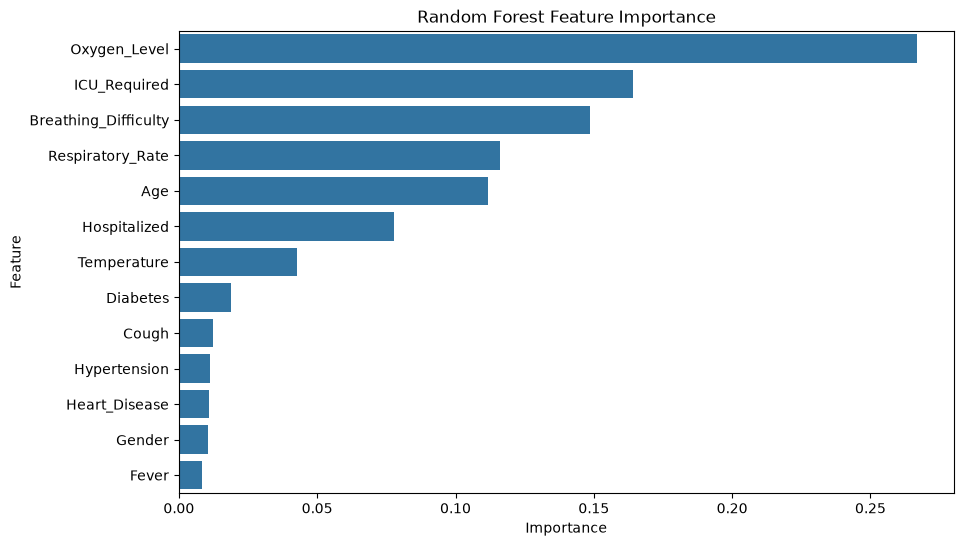

In [33]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title(
    "Random Forest Feature Importance"
)

plt.show()

In [34]:
actual_predicted = pd.DataFrame({

    "Actual Outcome":
        outcome_encoder.inverse_transform(y_test),

    "Predicted Outcome":
        outcome_encoder.inverse_transform(y_pred)

})

actual_predicted.head(20)

,Actual Outcome,Predicted Outcome
0,Death,Death
1,Death,Death
2,Recovered,Recovered
3,ICU,ICU
4,Death,Death
5,Death,ICU
6,Recovered,ICU
7,Death,Death
8,ICU,ICU
9,ICU,Death


In [35]:
new_patient = pd.DataFrame({

    "Age": [55],

    "Gender": [
        gender_encoder.transform(["Male"])[0]
    ],

    "Fever": [1],

    "Cough": [1],

    "Breathing_Difficulty": [1],

    "Diabetes": [1],

    "Hypertension": [1],

    "Heart_Disease": [0],

    "Oxygen_Level": [89],

    "Respiratory_Rate": [28],

    "Temperature": [38.5],

    "Hospitalized": [1],

    "ICU_Required": [1]

})

new_prediction = model.predict(
    new_patient
)

result = outcome_encoder.inverse_transform(
    new_prediction
)

print(
    "Predicted Outcome:",
    result[0]
)

Predicted Outcome: Death


In [36]:
import joblib

joblib.dump(
    model,
    "covid_random_forest_model.pkl"
)

joblib.dump(
    gender_encoder,
    "gender_encoder.pkl"
)

joblib.dump(
    outcome_encoder,
    "outcome_encoder.pkl"
)

print("Model and encoders saved successfully!")

Model and encoders saved successfully!
